In [1]:
import os, glob, pickle, numpy as np
import pandas as pd

# ---------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------
MI_DIR_MORE = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/gene_network_calcs/"
    "mi_group_mt_and_random_sets_results_more_combos"
)

MI_FILE_150_ORIG = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/gene_network_calcs/"
    "mi_group_mt_and_random_sets_results/"
    "MI_mito_random_samples_treutlein_150_numba.pkl"
)

# ---------------------------------------------------------------------
# Collect files
# ---------------------------------------------------------------------
pkls = sorted(glob.glob(os.path.join(MI_DIR_MORE, "*treutlein*numba.pkl")))
if os.path.exists(MI_FILE_150_ORIG):
    pkls.append(MI_FILE_150_ORIG)

if not pkls:
    raise FileNotFoundError("No treutlein files found.")

print("\nFound files:\n")
for p in pkls:
    print("  ", os.path.basename(p))

print("\n--- Detailed inspection ---\n")

audit_rows = []

for pkl in pkls:
    with open(pkl, "rb") as f:
        content = pickle.load(f)

    filename = os.path.basename(pkl)

    # Type + length check
    content_type = type(content)
    total_len = len(content) if hasattr(content, "__len__") else None

    if isinstance(content, (list, tuple)) and total_len >= 2:
        mito_val = content[-1]
        random_vals = content[:-1]
    else:
        print(f"[ERROR] Unexpected structure in {filename}")
        print("Type:", content_type)
        print("Length:", total_len)
        continue

    random_vals = np.asarray(random_vals, dtype=float)

    audit_rows.append({
        "file": filename,
        "total_entries": total_len,
        "n_random": len(random_vals),
        "n_MT": 1,
        "random_mean": float(np.mean(random_vals)),
        "random_std": float(np.std(random_vals, ddof=1)) if len(random_vals) > 1 else np.nan,
        "MT_value": float(mito_val),
        "random_min": float(np.min(random_vals)),
        "random_max": float(np.max(random_vals)),
        "MT_equals_last_random": bool(mito_val == random_vals[-1]) if len(random_vals) > 0 else False,
    })

audit_df = pd.DataFrame(audit_rows).sort_values("n_random").reset_index(drop=True)

print(audit_df.to_string(index=False))



Found files:

   MI_mito_random_samples_treutlein_1000_numba.pkl
   MI_mito_random_samples_treutlein_300_numba.pkl
   MI_mito_random_samples_treutlein_600_numba.pkl
   MI_mito_random_samples_treutlein_150_numba.pkl

--- Detailed inspection ---

                                           file  total_entries  n_random  n_MT  random_mean  random_std  MT_value  random_min  random_max  MT_equals_last_random
 MI_mito_random_samples_treutlein_150_numba.pkl            151       150     1     5.217989    1.679211  9.491988    1.645034    8.902777                  False
 MI_mito_random_samples_treutlein_300_numba.pkl            301       300     1     4.951259    1.635695  9.491988    0.783347    9.004584                  False
 MI_mito_random_samples_treutlein_600_numba.pkl            601       600     1     4.951416    1.588467  9.491988    1.291153    9.106119                  False
MI_mito_random_samples_treutlein_1000_numba.pkl           1001      1000     1     4.918704    1.633214  9.491

Treutlein entropy H = 9.49199

Summary table:

 n_random  mito_norm  random_mean_norm  random_std_norm   p_norm stars                                            file
      150        1.0          0.549726         0.176908 0.006623    **  MI_mito_random_samples_treutlein_150_numba.pkl
      300        1.0          0.521625         0.172324 0.003322    **  MI_mito_random_samples_treutlein_300_numba.pkl
      600        1.0          0.521642         0.167348 0.001664    **  MI_mito_random_samples_treutlein_600_numba.pkl
     1000        1.0          0.518195         0.172062 0.000999   *** MI_mito_random_samples_treutlein_1000_numba.pkl


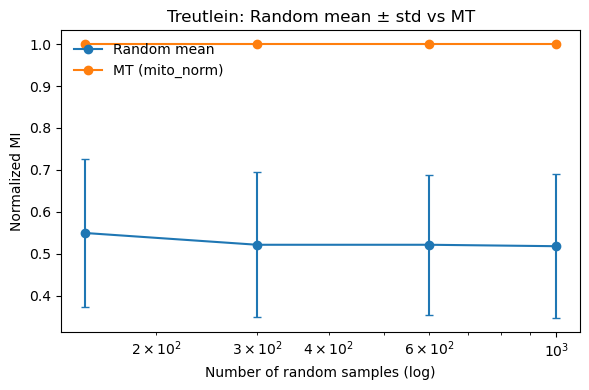

In [6]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =====================================================
# 0) INPUT: treutlein dataframe path (for entropy)
# =====================================================
DF_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered"
)
TREUTLEIN_DF = DF_DIR / "treutlein_all_genes.pkl"

# pkls should already exist from your audit cell.
# If not, uncomment and re-create pkls here.
# pkls = [...]

# =====================================================
# 1) HELPERS
# =====================================================
def calculate_entropy(labels: np.ndarray) -> float:
    labels = np.asarray(labels)
    labels = labels[~pd.isna(labels)]
    if labels.size == 0:
        return np.nan
    uniq, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())

def empirical_two_tailed_p(random_vals: np.ndarray, x0: float) -> float:
    """
    Two-tailed empirical p-value with +1 correction:
      p = (1 + #{|r-mu| >= |x0-mu|}) / (N + 1)
    """
    r = np.asarray(random_vals, dtype=float)
    mu = float(np.mean(r))
    obs = abs(float(x0) - mu)
    more_extreme = np.sum(np.abs(r - mu) >= obs)
    return float((1.0 + more_extreme) / (r.size + 1.0))

def get_pval_stars(p_val: float) -> str:
    if p_val > 5.00e-02:
        return "ns"
    elif 1.00e-02 < p_val <= 5.00e-02:
        return "*"
    elif 1.00e-03 < p_val <= 1.00e-02:
        return "**"
    elif 1.00e-04 < p_val <= 1.00e-03:
        return "***"
    else:
        return "****"

# =====================================================
# 2) LOAD entropy for normalization (same as your pipeline)
# =====================================================
with open(TREUTLEIN_DF, "rb") as f:
    df = pickle.load(f)

if "barcode_cont" not in df.columns:
    raise KeyError(f"'barcode_cont' column not found in {TREUTLEIN_DF}")

barcodes = np.round(df["barcode_cont"].values, decimals=1)
H = calculate_entropy(barcodes)
if H <= 0 or np.isnan(H):
    raise ValueError(f"treutlein: entropy is {H} (cannot normalize).")

print(f"Treutlein entropy H = {H:.6g}")

# =====================================================
# 3) BUILD results table (res)
# =====================================================
rows = []
for pkl_path in pkls:
    with open(pkl_path, "rb") as f:
        content = pickle.load(f)

    fn = os.path.basename(pkl_path)

    if not isinstance(content, (list, tuple)) or len(content) < 2:
        raise ValueError(f"Unexpected content in {fn}: type={type(content)}, len={len(content) if hasattr(content,'__len__') else None}")

    mito_raw = float(content[-1])
    random_raw = np.asarray(content[:-1], dtype=float)

    mito_norm = mito_raw / H
    random_norm = random_raw / H

    p_norm = empirical_two_tailed_p(random_norm, mito_norm)

    rows.append({
        "file": fn,
        "path": pkl_path,
        "n_random": int(random_raw.size),
        "mito_norm": float(mito_norm),
        "random_mean_norm": float(np.mean(random_norm)),
        "random_std_norm": float(np.std(random_norm, ddof=1)) if random_raw.size > 1 else np.nan,
        "p_norm": float(p_norm),
        "stars": get_pval_stars(p_norm),
    })

res = pd.DataFrame(rows).sort_values(["n_random", "file"]).reset_index(drop=True)

display_cols = ["n_random","mito_norm","random_mean_norm","random_std_norm","p_norm","stars","file"]
print("\nSummary table:\n")
print(res[display_cols].to_string(index=False))

# =====================================================
# 5) PLOT 2: MI plot (random mean ± std + MT as line)
# =====================================================
plt.figure(figsize=(6,4))

plt.plot(res["n_random"], res["random_mean_norm"], marker="o", label="Random mean")
plt.errorbar(
    res["n_random"], res["random_mean_norm"],
    yerr=res["random_std_norm"],
    fmt="none", capsize=3
)

plt.plot(res["n_random"], res["mito_norm"], marker="o", label="MT (mito_norm)")

plt.xscale("log")
plt.xlabel("Number of random samples (log)")
plt.ylabel("Normalized MI")
plt.title("Treutlein: Random mean ± std vs MT")
plt.legend(frameon=False)
plt.savefig("gene_groups_more_combos_treutlein.pdf", bbox_inches = "tight")
plt.tight_layout()
plt.show()